# Strategii primare ETH: L10, L03, A12L, L1

Notebook-ul implementează cele 4 strategii primare (doar reguli, fără ML), le backtestează și raportează statistici economice și grafice.

| Strategie | Evenimente | Regula | Side |
|---|---|---|---|
| **L10_capitulation** | CUSUM fix 0,05 | eveniment **down** + mișcarea mai rapidă decât mediana ultimelor 100 de mișcări + notional/s în timpul mișcării > 2× mediana pe 7 zile | LONG |
| **L03_fast_dn_reversal** | CUSUM fix 0,05 | eveniment **down** + mișcarea mai rapidă decât mediana ultimelor 100 de mișcări | LONG |
| **A12L_persistent_us_demand** | CUSUM dinamic (σ_bară·√15) | eveniment **up** + premium Coinbase ETH (60 min) peste mediana pe 7 zile + peste mediană în > 50% din ultimele 24 h | LONG |
| **L1_spot_led_breakout** | CUSUM dinamic (σ_bară·√15) | eveniment **up** + premium Coinbase ETH (60 min) peste mediana pe 7 zile | LONG |

### Cum se calculează profitul

Profitul pe trade este **`side × ret`**, unde `ret` vine din `trend_scanning_labels` (mlfinpy):

$$ret = \frac{close[t_1]}{close[t_0]} - 1$$

- `t0` = bara evenimentului (intrare la close).
- `t1` = capătul ferestrei de 10–19 bare cu |t-value| maxim (ieșire la close). Nu există TP / SL.
- **`t_value` nu este profit.** E statistica t a trendului și o folosesc doar pentru *precision* (cât de des `sign(t_value)` = side, adică `bin == side`).

⚠️ `t1` e ales ex-post (fereastra cu trendul cel mai clar), deci nu e o ieșire implementabilă 1:1. Pentru o verificare implementabilă, schimbă `PNL_MODE = "fixed_bars"` în celula de configurare: ieșirea devine la un număr fix de bare.

### Cum adaugi o strategie nouă

Adaugi o linie în lista `STRATEGIES` (secțiunea 3) cu: nume, tipul de evenimente, side și o regulă scrisă ca `lambda`. Restul notebook-ului (backtest, statistici, grafice) se adaptează automat.

## 0. Încărcarea datelor

In [1]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"
volume_100 = pd.read_parquet(DATASETS_DIR / "SOLUSDT_spot_volume_84200_50pd_20210901-20260901_52d81b48/volume.parquet")

In [2]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(volume_100)
df = df[~df.index.duplicated(keep='first')]

In [3]:
# Calculate percentage of missing values
null_pct = df.isna().mean() * 100

# Identify columns with more than 1% missing values
cols_to_drop = null_pct[null_pct > 1]

# Display columns to be removed
print(cols_to_drop.sort_values(ascending=False).to_string())

# Remove columns
df = df.drop(columns=cols_to_drop.index)

print(f"\nRemoved {len(cols_to_drop)} columns.")
print(f"Remaining columns: {df.shape[1]}")

etf_btc_net_flow_total_usd_economic_age_d              100.000000
etf_btc_net_flow_total_usd_age_s                       100.000000
etf_btc_net_flow_total_usd                             100.000000
etf_btc_net_flow_total_usd_z60                         100.000000
etf_btc_sum_reported_funds_usd_economic_age_d          100.000000
etf_btc_sum_reported_funds_usd_age_s                   100.000000
etf_btc_sum_reported_funds_usd                         100.000000
etf_btc_n_funds_reported_age_s                         100.000000
etf_btc_n_funds_reported_economic_age_d                100.000000
etf_eth_net_flow_total_usd                             100.000000
etf_btc_n_funds_reported                               100.000000
etf_eth_net_flow_total_usd_age_s                       100.000000
etf_eth_sum_reported_funds_usd                         100.000000
etf_eth_net_flow_total_usd_z60                         100.000000
etf_eth_net_flow_total_usd_economic_age_d              100.000000
cost_sell_

In [4]:
from mlfinpy.labeling import trend_scanning_labels

tr_scan_labels = trend_scanning_labels(
    price_series=df['close'],
    t_events=df['close'].index,
    look_forward_window=20,
    min_sample_length=10
)

df = pd.concat([df, tr_scan_labels], axis=1)
df = df.loc[:, ~df.columns.duplicated(keep="last")]   # siguranță dacă etichetele existau deja

In [6]:
print(list(df.columns))

['bar_id', 'series_id', 'bar_type', 'bar_seq', 'segment_id', 'bar_start_us', 'bar_end_us', 'first_trade_ts_us', 'last_trade_ts_us', 'first_trade_id', 'last_trade_id', 'open', 'high', 'low', 'close', 'volume', 'notional_usdt', 'n_trades', 'n_messages', 'threshold_frozen', 'complete', 'bar_status', 'bar_available_us', 'decision_time_us', 'bar_provenance', 'bar_start', 'bar_end', 'bar_available', 'decision_time', 'ret_bars_1', 'ret_bars_5', 'ret_bars_20', 'ret_5min', 'ret_5min_ref_age_s', 'ret_1h', 'ret_1h_ref_age_s', 'ret_4h', 'ret_4h_ref_age_s', 'ret_1d', 'ret_1d_ref_age_s', 'ret_7d', 'ret_7d_ref_age_s', 'ret_30d', 'ret_30d_ref_age_s', 'rv_1h', 'rvol_1h', 'rvol_ann_1h', 'rv_1d', 'rvol_1d', 'rvol_ann_1d', 'rv_7d', 'rvol_7d', 'rvol_ann_7d', 'rv_bars_20', 'rv_bars_100', 'bar_duration_s', 'trade_span_s', 'avg_trade_size', 'trade_intensity_per_s', 'volume_per_s', 'notional_per_s', 'aggr_buy_volume', 'aggr_sell_volume', 'aggr_signed_volume', 'aggr_classified_frac_volume', 'aggr_imbalance_volu

## 1. Configurare

Toți parametrii de backtest sunt aici. Regulile strategiilor **nu** se optimizează: sunt cele fixate și testate în rapoartele v1–v3.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from dataclasses import dataclass
from typing import Callable
from scipy.stats import norm, skew, kurtosis
from mlfinpy.filters import cusum_filter

# --- perioade
SPLIT_DATE = pd.Timestamp("2025-09-01", tz="UTC")   # dev < SPLIT_DATE <= holdout

# --- profit
PNL_MODE = "ret"          # "ret" = side * ret (trend scanning, ieșire la t1) | "fixed_bars" = ieșire după FIXED_BARS bare
FIXED_BARS = 15
COST_BPS_ROUNDTRIP = 0.0  # cost dus-întors în bps aplicat fiecărui trade (0 = brut). Binance spot taker ≈ 20
COST_SCENARIOS_BPS = [0, 5, 10, 20]

# --- bani
INITIAL_CAPITAL = 10_000  # USD
TRADE_NOTIONAL = 10_000   # USD investiți în fiecare trade (fix, fără compunere)

# --- PSR / DSR
ANN_DAYS = 365            # crypto se tranzacționează 365 de zile
N_TRIALS = 78             # câte strategii au fost testate în total în rundele v1–v3 (a treia lege a backtesting-ului)
SR_VAR_TRIALS = 0.000869  # varianța Sharpe-ului ZILNIC între cele 78 de încercări (estimată pe dev în v1–v3)

REQUIRED = ["close", "notional_usdt", "notional_per_s", "premium_fx_coinbase_sol_1m", "t1", "t_value", "ret", "bin"]
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"Lipsesc coloanele necesare: {missing}"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#e4e3df", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
print(f"Date: {df.index.min()} -> {df.index.max()}, {len(df):,} bare")

Date: 2021-09-01 00:06:55.986000+00:00 -> 2026-08-31 22:29:34.229839+00:00, 91,222 bare


## 2. Evenimente și features

`cusum_with_runs` are aceeași logică ca `mlfinpy.filters.cusum_filter` (verificat cu `assert`), dar păstrează în plus:
- **`cusum_side`**: +1 dacă s-a declanșat acumulatorul de creștere, −1 dacă s-a declanșat cel de scădere;
- **`run_start`**: bara la care acumulatorul declanșator a fost ultima dată 0, adică începutul mișcării.

Pe baza lor calculez durata mișcării (`run_hours`), dacă a fost **rapidă** (`fast`, sub mediana ultimelor 100 de mișcări, folosind doar trecutul) și **intensitatea** volumului în timpul mișcării (`intensity_rel`).

In [8]:
def cusum_with_runs(close: pd.Series, threshold) -> pd.DataFrame:
    """CUSUM simetric pe log(close), identic cu mlfinpy.cusum_filter.
    threshold: float sau pd.Series aliniat cu close."""
    lr = np.log(close).diff().values
    h = np.full(len(close), float(threshold)) if np.isscalar(threshold) else threshold.reindex(close.index).values
    s_pos = s_neg = 0.0
    p_start = n_start = 0
    rows = []
    for i in range(1, len(close)):
        s_pos = max(0.0, s_pos + lr[i])
        s_neg = min(0.0, s_neg + lr[i])
        if s_pos == 0.0:
            p_start = i
        if s_neg == 0.0:
            n_start = i
        if s_neg < -h[i]:
            rows.append((i, -1, n_start)); s_neg, n_start = 0.0, i
        elif s_pos > h[i]:
            rows.append((i, +1, p_start)); s_pos, p_start = 0.0, i
    pos, side, start = map(np.array, zip(*rows))
    ev = pd.DataFrame({"cusum_side": side, "bar_pos": pos, "start_pos": start}, index=close.index[pos])
    ev["run_start"] = close.index[start]
    return ev


def add_run_features(ev: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    ev = ev.copy()
    dur_s = (ev.index.to_series() - ev["run_start"]).dt.total_seconds()
    ev["run_hours"] = dur_s / 3600
    # rapid = mai scurt decât mediana ultimelor 100 de mișcări (doar evenimente anterioare)
    med_prev = ev["run_hours"].shift(1).rolling(100, min_periods=30).median()
    ev["fast"] = (ev["run_hours"] < med_prev) & med_prev.notna()
    # intensitate: notional/s în timpul mișcării raportat la mediana pe 7 zile a notional/s
    cum_not = np.r_[0.0, df["notional_usdt"].fillna(0).cumsum().values]
    med7 = df["notional_per_s"].rolling("7D").median().values
    ev["intensity_rel"] = (cum_not[ev.bar_pos + 1] - cum_not[ev.start_pos + 1]) / dur_s.clip(lower=1).values / med7[ev.bar_pos]
    return ev


def bar_state_features(df: pd.DataFrame) -> pd.DataFrame:
    """Starea pieței la fiecare bară, calculată doar din trecut."""
    p = df["premium_fx_coinbase_sol_1m"]                 # premium Coinbase ETH-USD vs Binance ETH-USDT, ajustat FX
    med7 = p.rolling("7D").median()
    S = pd.DataFrame(index=df.index)
    S["cbp_ex_60min"] = p.rolling("60min").mean() - med7     # premium (60 min) peste norma pe 7 zile
    S["cbp_pos_frac_24h"] = (p > med7).astype(float).rolling("24h").mean()   # persistența cererii US în ultimele 24 h
    return S


close = df["close"]
STATE = bar_state_features(df)

# prag dinamic: σ ex-ante al unei bare (din ultimele 100 de bare, până la bara anterioară) × √15
rv100 = (np.log(close).diff() ** 2).rolling(100).sum()
h_dyn = (np.sqrt(rv100.shift(1) / 100) * np.sqrt(15)).bfill()

EVENTS = {}
for key, thr in {"cusum_005": 0.05, "cusum_dyn": h_dyn}.items():
    ev = cusum_with_runs(close, thr)
    assert ev.index.equals(cusum_filter(close, threshold=thr)), f"{key}: diferă de mlfinpy"
    EVENTS[key] = add_run_features(ev, df).join(STATE)
    print(f"{key}: {len(ev):,} evenimente (up {int((ev.cusum_side > 0).sum()):,} / down {int((ev.cusum_side < 0).sum()):,}) - identic cu mlfinpy.cusum_filter")

cusum_005: 2,952 evenimente (up 1,488 / down 1,464) - identic cu mlfinpy.cusum_filter
cusum_dyn: 7,410 evenimente (up 3,716 / down 3,694) - identic cu mlfinpy.cusum_filter


## 3. Strategiile

Fiecare strategie e un obiect `Strategy`. Ca să adaugi una nouă, scrii o linie în listă. `rule` primește tabelul de evenimente și întoarce o mască booleană.

In [9]:
@dataclass
class Strategy:
    name: str
    events: str                                   # cheie din EVENTS
    side: int                                     # +1 long / -1 short
    rule: Callable[[pd.DataFrame], pd.Series]     # condiția pe tabelul de evenimente
    description: str = ""


STRATEGIES = [
    Strategy("L10_capitulation", "cusum_005", +1,
             lambda e: (e.cusum_side == -1) & e.fast & (e.intensity_rel > 2),
             "Scădere de 5% rapidă, pe volum > 2x normal = vânzare forțată -> revenire"),
    Strategy("L03_fast_dn_reversal", "cusum_005", +1,
             lambda e: (e.cusum_side == -1) & e.fast,
             "Scădere de 5% mai rapidă decât de obicei = flux forțat -> revenire"),
    Strategy("A12L_persistent_us_demand", "cusum_dyn", +1,
             lambda e: (e.cusum_side == 1) & (e.cbp_ex_60min > 0) & (e.cbp_pos_frac_24h > 0.5),
             "Creștere susținută de cerere US persistentă (premium Coinbase) -> continuare"),
    Strategy("L1_spot_led_breakout", "cusum_dyn", +1,
             lambda e: (e.cusum_side == 1) & (e.cbp_ex_60min > 0),
             "Creștere confirmată de premium Coinbase peste normă -> continuare"),
]
NAMES = [s.name for s in STRATEGIES]
COLOR = dict(zip(NAMES, COLORS))

## 4. Trade-uri

Un rând = un trade. `gross_ret = side × ret`, `net_ret = gross_ret − cost`, `pnl_usd = TRADE_NOTIONAL × net_ret`.

In [10]:
def fixed_bars_exit(df, entry_times, n):
    pos = df.index.get_indexer(entry_times)
    out = np.minimum(pos + n, len(df) - 1)
    ret = df["close"].values[out] / df["close"].values[pos] - 1
    ret[pos + n >= len(df)] = np.nan
    return df.index[out], ret


def build_trades(strategies, events, df):
    rows = []
    for s in strategies:
        E = events[s.events]
        sel = E[s.rule(E).fillna(False).astype(bool)]
        T = pd.DataFrame(index=sel.index)
        T["strategy"], T["side"] = s.name, s.side
        T["t0"] = sel.index
        if PNL_MODE == "ret":
            lab = df.loc[sel.index, ["t1", "ret", "t_value", "bin"]]
            T["t1"] = pd.to_datetime(lab["t1"], utc=True)
            T["ret"] = lab["ret"].astype(float)
        else:
            T["t1"], T["ret"] = fixed_bars_exit(df, sel.index, FIXED_BARS)
            lab = df.loc[sel.index, ["t_value", "bin"]]
        T["t_value"], T["bin"] = lab["t_value"].astype(float), lab["bin"].astype(float)
        rows.append(T)
    T = pd.concat(rows).dropna(subset=["t1", "ret"])
    T["gross_ret"] = T.side * T.ret
    T["net_ret"] = T.gross_ret - COST_BPS_ROUNDTRIP / 1e4
    T["pnl_usd"] = TRADE_NOTIONAL * T.net_ret
    T["hold_hours"] = (T.t1 - T.t0).dt.total_seconds() / 3600
    T["period"] = np.where(T.t0 < SPLIT_DATE, "dev", "holdout")
    T["trend_correct"] = (T.bin == T.side)
    return T.reset_index(drop=True)


TRADES = build_trades(STRATEGIES, EVENTS, df)
print(TRADES.groupby(["strategy", "period"]).size().unstack().reindex(NAMES).to_string())
TRADES.head()

period                      dev  holdout
strategy                                
L10_capitulation            195       25
L03_fast_dn_reversal        606       77
A12L_persistent_us_demand  1007      163
L1_spot_led_breakout       1688      277


,strategy,side,t0,t1,ret,t_value,bin,gross_ret,net_ret,pnl_usd,hold_hours,period,trend_correct
0,L10_capitulation,1,2021-09-07 14:29:55.828000+00:00,2021-09-07 15:03:00.712000+00:00,-0.057831,-5.156276,-1.0,-0.057831,-0.057831,-578.311827,0.551357,dev,False
1,L10_capitulation,1,2021-09-07 14:47:51.984000+00:00,2021-09-07 15:10:10.362000+00:00,-0.196353,-5.505846,-1.0,-0.196353,-0.196353,-1963.532622,0.371772,dev,False
2,L10_capitulation,1,2021-09-07 14:59:27.735000+00:00,2021-09-07 15:10:10.362000+00:00,-0.169359,-6.134556,-1.0,-0.169359,-0.169359,-1693.589744,0.178507,dev,False
3,L10_capitulation,1,2021-09-07 15:07:38.260000+00:00,2021-09-07 15:25:24.941000+00:00,0.109103,6.911528,1.0,0.109103,0.109103,1091.034483,0.296300,dev,True
4,L10_capitulation,1,2021-09-07 15:09:43.809000+00:00,2021-09-07 15:24:12.381000+00:00,0.222524,8.899210,1.0,0.222524,0.222524,2225.235405,0.241270,dev,True


## 5. PSR și DSR: merită folosite?

**Da, amândouă**, din motive diferite:

- **PSR** (probabilitatea ca Sharpe-ul real să fie > 0) e necesar aici pentru că randamentele nu sunt gaussiene. PnL-ul zilnic al acestor strategii are kurtosis de 10–100 (multe zile fără trade, câteva zile cu mișcări mari), iar istoricul diferă mult între strategii (~28 de trade-uri pe an pentru L10, ~800 pentru L1). Sharpe-ul simplu le pune pe același plan; PSR nu.
- **DSR** e esențial pentru că aceste 4 strategii au fost alese din **78 de încercări** (v1–v3). Sharpe-ul celei mai bune dintre 78 de strategii fără niciun edge ar fi oricum pozitiv. DSR compară Sharpe-ul cu maximul așteptat din pură șansă: `N_TRIALS = 78` și `SR_VAR_TRIALS` = varianța Sharpe-urilor zilnice dintre cele 78 de încercări.

**Citire:** ≥ 0,95 înseamnă semnificativ la 5%.
- Pe **holdout**, PSR e testul relevant: pe această perioadă nu s-a selectat nimic în runda în care strategiile au fost alese.
- Pe **dev / full**, DSR e testul corect, pentru că acolo s-a făcut selecția.

⚠️ Dacă testezi alte variante, crește `N_TRIALS` (a treia lege a backtesting-ului).

Ambele se calculează pe **PnL-ul zilnic** (cu zilele fără trade = 0), cu Sharpe-ul neanualizat în formulă.

In [11]:
EULER = 0.5772156649

def psr(sr, T, g3, g4, sr_star=0.0):
    """Probabilistic Sharpe Ratio (Bailey & López de Prado 2012). sr pe perioada de bază (zilnic), g4 = kurtosis (normal = 3)."""
    den = np.sqrt(max(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2, 1e-12))
    return float(norm.cdf((sr - sr_star) * np.sqrt(T - 1) / den))


def expected_max_sr(n_trials, sr_var):
    """SR* = Sharpe-ul maxim așteptat între N încercări fără edge (Bailey & López de Prado 2014)."""
    return np.sqrt(sr_var) * ((1 - EULER) * norm.ppf(1 - 1 / n_trials) + EULER * norm.ppf(1 - 1 / (n_trials * np.e)))


SR_STAR_DSR = expected_max_sr(N_TRIALS, SR_VAR_TRIALS)
print(f"SR* (DSR) = {SR_STAR_DSR:.4f} zilnic = {SR_STAR_DSR * np.sqrt(ANN_DAYS):.2f} anualizat")

SR* (DSR) = 0.0720 zilnic = 1.38 anualizat


## 6. Statistici economice

In [12]:
def daily_pnl(T, start, end):
    days = pd.date_range(start.floor("D"), end.floor("D"), freq="D", tz="UTC")
    return T.groupby(T.t1.dt.floor("D")).pnl_usd.sum().reindex(days, fill_value=0.0)


def max_concurrent(T):
    ev = pd.concat([pd.Series(1, index=T.t0), pd.Series(-1, index=T.t1)]).sort_index(kind="stable")
    return int(ev.cumsum().max()) if len(ev) else 0


def exposure(T, start, end):
    iv = T[["t0", "t1"]].sort_values("t0").values
    tot, cur_s, cur_e = 0.0, None, None
    for s, e in iv:
        if cur_e is None or s > cur_e:
            if cur_e is not None:
                tot += (cur_e - cur_s).total_seconds()
            cur_s, cur_e = s, e
        else:
            cur_e = max(cur_e, e)
    if cur_e is not None:
        tot += (cur_e - cur_s).total_seconds()
    return tot / (end - start).total_seconds()


def stats(T, start, end):
    d = daily_pnl(T, start, end)
    r = d / INITIAL_CAPITAL                                     # randament zilnic pe capital
    years = (end - start).days / 365.25
    eq = d.cumsum()
    dd = eq - eq.cummax()
    sr_d = r.mean() / r.std() if r.std() > 0 else np.nan
    downside = np.sqrt(np.mean(np.minimum(r, 0) ** 2))         # downside deviation (ținta 0)
    wins, losses = T.net_ret[T.net_ret > 0], T.net_ret[T.net_ret <= 0]
    g3, g4 = skew(r), kurtosis(r, fisher=False)
    ann_ret = d.sum() / INITIAL_CAPITAL / years
    max_dd = dd.min()
    return {
        "trade-uri": len(T),
        "trade-uri / lună": len(T) / (years * 12),
        "trade-uri / săptămână": len(T) / (years * 52.18),
        "win rate": (T.net_ret > 0).mean(),
        "trend corect (bin = side)": T.trend_correct.mean(),
        "t_value mediu (× side)": (T.side * T.t_value).mean(),
        "medie / trade (bps)": T.net_ret.mean() * 1e4,
        "mediană / trade (bps)": T.net_ret.median() * 1e4,
        "câștig mediu (bps)": wins.mean() * 1e4,
        "pierdere medie (bps)": losses.mean() * 1e4,
        "profit factor": wins.sum() / -losses.sum() if losses.sum() < 0 else np.nan,
        "PnL total (USD)": d.sum(),
        "PnL / an (USD)": d.sum() / years,
        "randament anual (% capital)": ann_ret * 100,
        "Sharpe anualizat": sr_d * np.sqrt(ANN_DAYS),
        "Sortino anualizat": r.mean() / downside * np.sqrt(ANN_DAYS) if downside > 0 else np.nan,
        "max drawdown (USD)": max_dd,
        "max drawdown (% capital)": max_dd / INITIAL_CAPITAL * 100,
        "Calmar": ann_ret / (-max_dd / INITIAL_CAPITAL) if max_dd < 0 else np.nan,
        "zile cu PnL ≠ 0 (%)": (d != 0).mean() * 100,
        "durată medie trade (h)": T.hold_hours.mean(),
        "expunere (% timp)": exposure(T, start, end) * 100,
        "max poziții simultane": max_concurrent(T),
        "skew PnL zilnic": g3,
        "kurtosis PnL zilnic": g4,
        "PSR (SR* = 0)": psr(sr_d, len(r), g3, g4, 0.0),
        f"DSR (N = {N_TRIALS})": psr(sr_d, len(r), g3, g4, SR_STAR_DSR),
    }


PERIODS = {
    "FULL": (df.index.min(), df.index.max()),
    "DEV": (df.index.min(), SPLIT_DATE - pd.Timedelta("1ns")),
    "HOLDOUT": (SPLIT_DATE, df.index.max()),
}
STATS = {}
for pname, (a, b) in PERIODS.items():
    STATS[pname] = pd.DataFrame({n: stats(TRADES[(TRADES.strategy == n) & (TRADES.t0 >= a) & (TRADES.t0 <= b)], a, b)
                                 for n in NAMES})

fmt = lambda x: f"{x:,.2f}" if isinstance(x, (float, np.floating)) else f"{x:,}"
for pname, S in STATS.items():
    print(f"\n================ {pname}  ({PERIODS[pname][0].date()} -> {PERIODS[pname][1].date()}) ================")
    print(S.map(fmt).to_string())


================ FULL  (2021-09-01 -> 2026-08-31) ================
                            L10_capitulation L03_fast_dn_reversal A12L_persistent_us_demand L1_spot_led_breakout
trade-uri                             220.00               683.00                  1,170.00             1,965.00
trade-uri / lună                        3.67                11.39                     19.51                32.77
trade-uri / săptămână                   0.84                 2.62                      4.49                 7.54
win rate                                0.59                 0.54                      0.51                 0.51
trend corect (bin = side)               0.61                 0.55                      0.51                 0.51
t_value mediu (× side)                  1.45                 0.65                     -0.03                -0.02
medie / trade (bps)                   109.86                43.64                     -2.48                -0.03
mediană / trade (bps)       

**Cum se citește:**
- `win rate` = % trade-uri cu profit.
- `trend corect` = % în care `sign(t_value)` = side.
- `profit factor` = Σ câștiguri / Σ pierderi.
- `randament anual` = PnL anual / `INITIAL_CAPITAL`, fără compunere.
- `max poziții simultane` > 1 înseamnă că, în acel moment, capitalul angajat a depășit `TRADE_NOTIONAL`.

## 7. Evoluția banilor

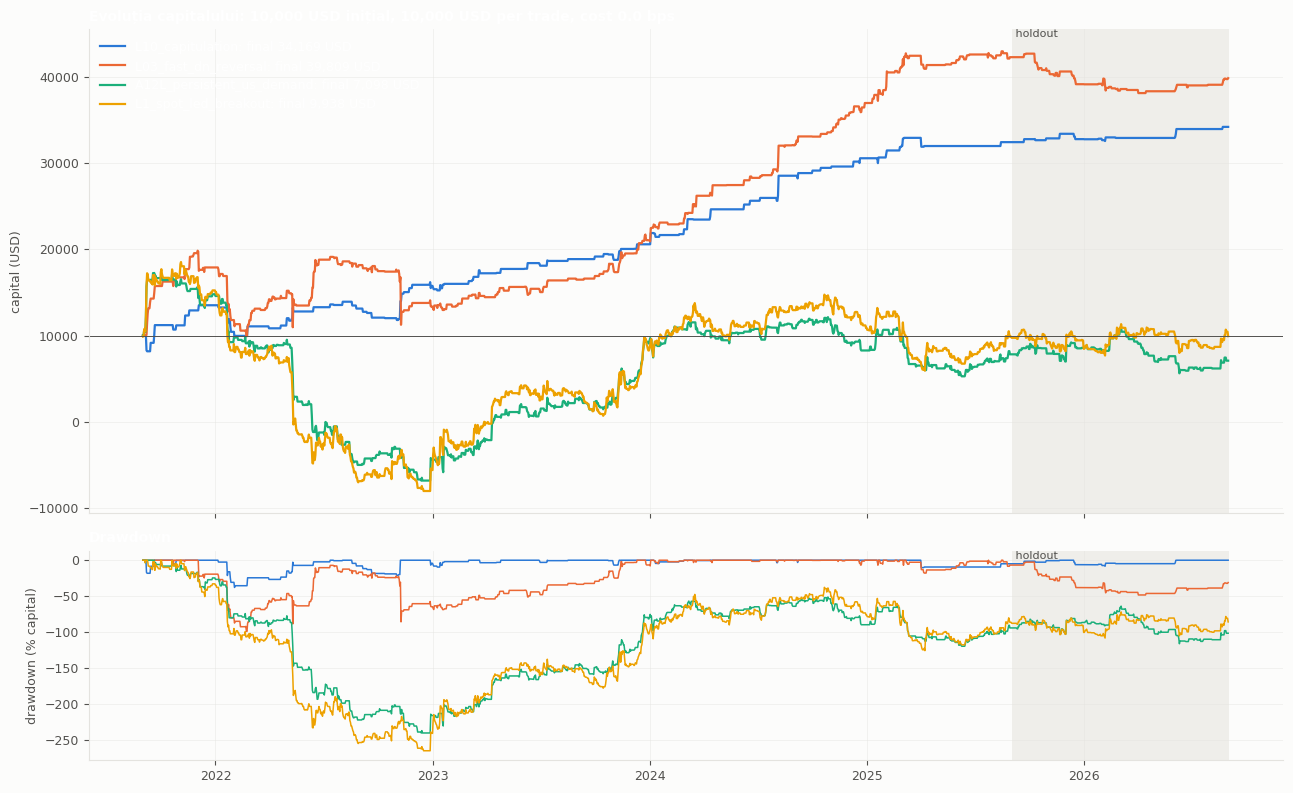

In [13]:
def shade_holdout(ax):
    ax.axvspan(SPLIT_DATE, df.index.max(), color="#efeeea", lw=0, zorder=0)
    ax.text(SPLIT_DATE, 1.0, " holdout", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color="#52514e")

start, end = df.index.min(), df.index.max()
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
for n in NAMES:
    d = daily_pnl(TRADES[TRADES.strategy == n], start, end)
    eq = INITIAL_CAPITAL + d.cumsum()
    axes[0].plot(eq.index, eq.values, color=COLOR[n], lw=1.6, label=f"{n}: final {eq.iloc[-1]:,.0f} USD")
    dd = (d.cumsum() - d.cumsum().cummax()) / INITIAL_CAPITAL * 100
    axes[1].plot(dd.index, dd.values, color=COLOR[n], lw=1.1)
axes[0].axhline(INITIAL_CAPITAL, color="#52514e", lw=0.7)
axes[0].set_ylabel("capital (USD)")
axes[0].set_title(f"Evoluția capitalului: {INITIAL_CAPITAL:,} USD inițial, {TRADE_NOTIONAL:,} USD per trade, cost {COST_BPS_ROUNDTRIP} bps", loc="left")
axes[0].legend(frameon=False, loc="upper left")
axes[1].set_ylabel("drawdown (% capital)")
axes[1].set_title("Drawdown", loc="left")
for ax in axes:
    shade_holdout(ax)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

## 8. Câți bani face fiecare strategie: pe an, trimestru și lună

PnL pe an (USD):
strategy  L10_capitulation  L03_fast_dn_reversal  A12L_persistent_us_demand  L1_spot_led_breakout
t1                                                                                               
2021                3516.0                7893.0                     4793.0                5236.0
2022                2239.0               -4538.0                   -19154.0              -20805.0
2023                4819.0                7689.0                    13457.0               13847.0
2024                9963.0               15891.0                     -816.0                2617.0
2025                2214.0                2177.0                      315.0               -2420.0
2026                1418.0                 698.0                    -1496.0                1462.0


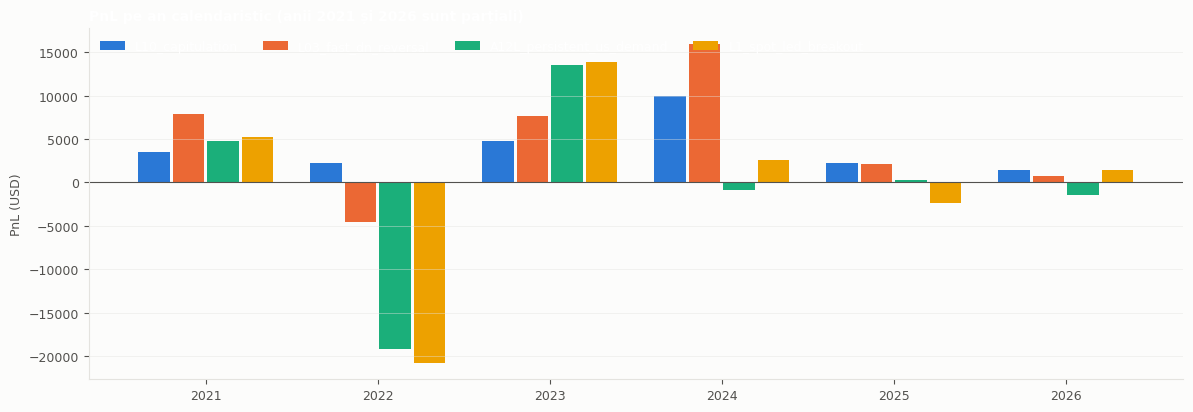

In [14]:
def pnl_by(freq_label):
    T = TRADES.copy()
    if freq_label == "an":
        key = T.t1.dt.year
    elif freq_label == "trimestru":
        key = T.t1.dt.tz_localize(None).dt.to_period("Q").astype(str)
    else:
        key = T.t1.dt.tz_localize(None).dt.to_period("M").astype(str)
    return T.pivot_table(index=key, columns="strategy", values="pnl_usd", aggfunc="sum", fill_value=0.0)[NAMES]

PNL_Y, PNL_Q, PNL_M = pnl_by("an"), pnl_by("trimestru"), pnl_by("lună")
print("PnL pe an (USD):"); print(PNL_Y.round(0).to_string())

fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(PNL_Y)); w = 0.8 / len(NAMES)
for k, n in enumerate(NAMES):
    ax.bar(x + (k - (len(NAMES) - 1) / 2) * w, PNL_Y[n].values, width=w * 0.92, color=COLOR[n], label=n)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(x, PNL_Y.index.astype(str)); ax.set_ylabel("PnL (USD)")
ax.set_title("PnL pe an calendaristic (anii 2021 și 2026 sunt parțiali)", loc="left")
ax.legend(frameon=False, ncol=4, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

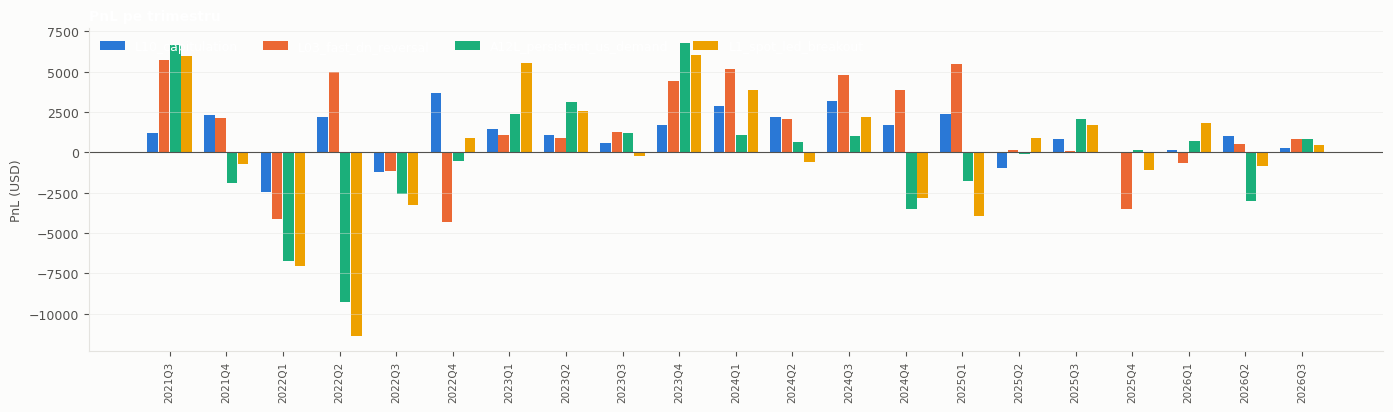

Trimestre pe profit (% din trimestrele cu cel puțin un trade):
strategy
L10_capitulation             86%
L03_fast_dn_reversal         76%
A12L_persistent_us_demand    57%
L1_spot_led_breakout         52%


In [15]:
fig, ax = plt.subplots(figsize=(14, 4.2))
x = np.arange(len(PNL_Q)); w = 0.8 / len(NAMES)
for k, n in enumerate(NAMES):
    ax.bar(x + (k - (len(NAMES) - 1) / 2) * w, PNL_Q[n].values, width=w * 0.92, color=COLOR[n], label=n)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(x, PNL_Q.index, rotation=90, fontsize=7.5); ax.set_ylabel("PnL (USD)")
ax.set_title("PnL pe trimestru", loc="left"); ax.legend(frameon=False, ncol=4, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("Trimestre pe profit (% din trimestrele cu cel puțin un trade):")
act = TRADES.assign(q=TRADES.t1.dt.tz_localize(None).dt.to_period("Q").astype(str)).groupby(["strategy", "q"]).pnl_usd.sum()
print((act > 0).groupby(level=0).mean().reindex(NAMES).map("{:.0%}".format).to_string())

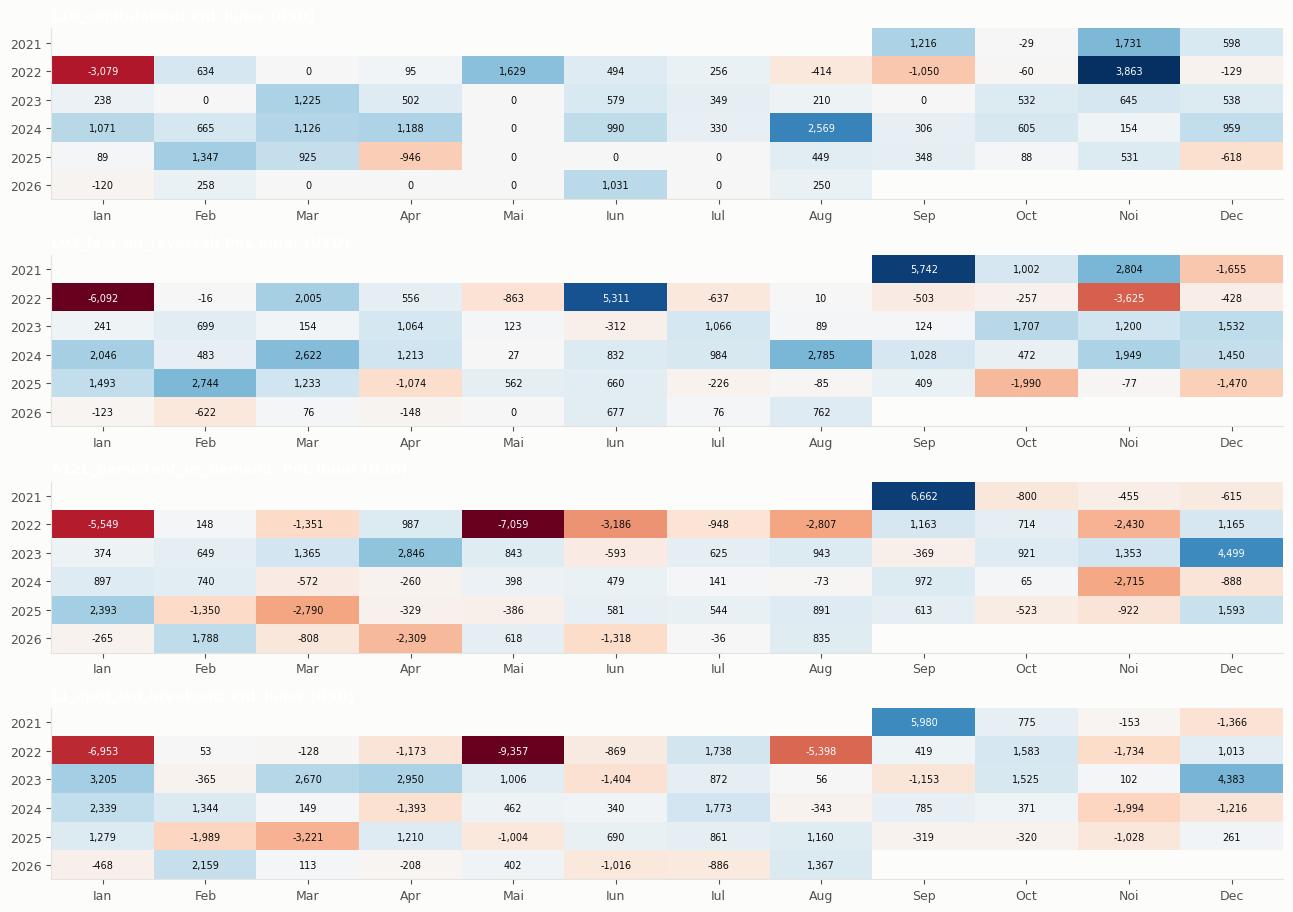

In [16]:
# heatmap lunar: rânduri = ani, coloane = luni, valori = PnL în USD
months = ["Ian", "Feb", "Mar", "Apr", "Mai", "Iun", "Iul", "Aug", "Sep", "Oct", "Noi", "Dec"]
fig, axes = plt.subplots(len(NAMES), 1, figsize=(13, 2.3 * len(NAMES)))
for ax, n in zip(np.atleast_1d(axes), NAMES):
    s = PNL_M[n]
    idx = pd.PeriodIndex(s.index, freq="M")
    H = pd.DataFrame({"y": idx.year, "m": idx.month, "v": s.values}).pivot(index="y", columns="m", values="v").reindex(columns=range(1, 13))
    lim = np.nanmax(np.abs(H.values)) or 1
    im = ax.imshow(H.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    for (i, j), v in np.ndenumerate(H.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.55 * lim else "#0b0b0b")
    ax.set_xticks(range(12), months); ax.set_yticks(range(len(H)), H.index); ax.grid(False)
    ax.set_title(f"{n}: PnL lunar (USD)", loc="left")
plt.tight_layout(); plt.show()

## 9. Câte semnale generează fiecare strategie

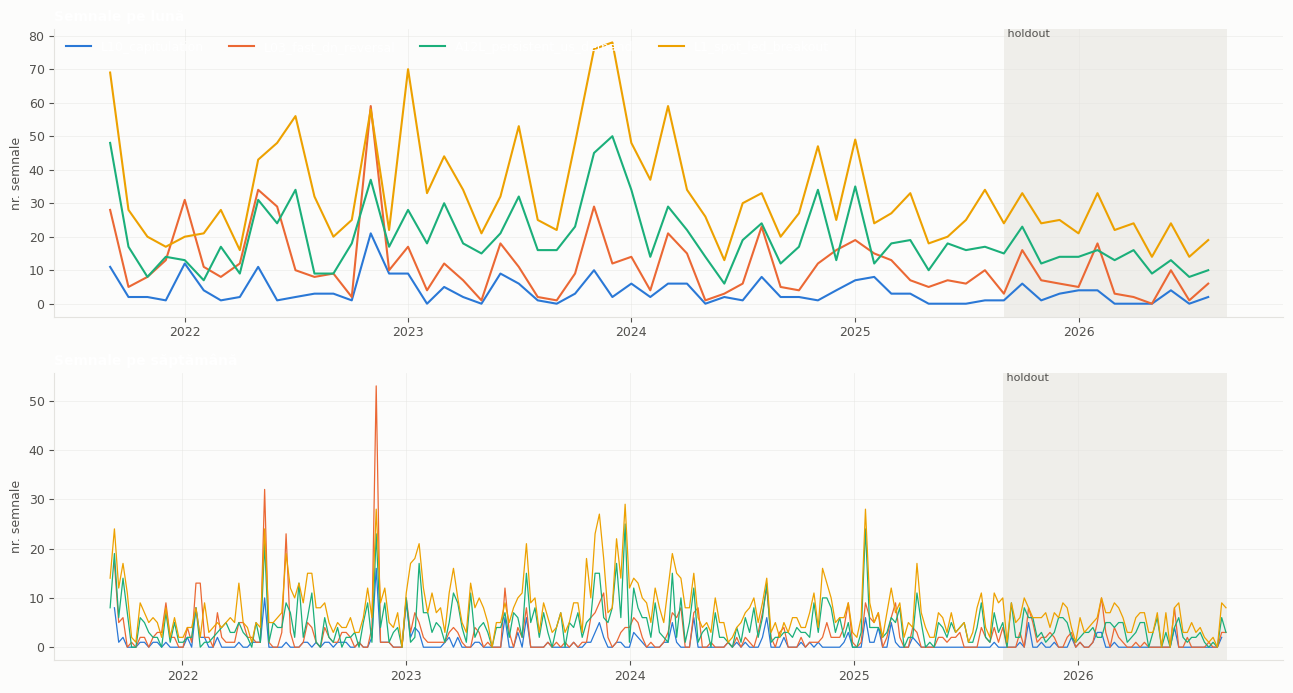

,total,medie / lună,max / lună,medie / săptămână (cu semnal),luni fără niciun semnal
strategy,,,,,
L10_capitulation,220,4.5,21,2.3,11
L03_fast_dn_reversal,683,11.6,59,4.0,1
A12L_persistent_us_demand,1170,19.5,50,5.0,0
L1_spot_led_breakout,1965,32.8,78,7.7,0


In [17]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for n in NAMES:
    t = TRADES[TRADES.strategy == n].set_index("t0")
    m = t.resample("MS").size(); wk = t.resample("W").size()
    axes[0].plot(m.index, m.values, color=COLOR[n], lw=1.5, label=n)
    axes[1].plot(wk.index, wk.values, color=COLOR[n], lw=0.9, label=n)
axes[0].set_title("Semnale pe lună", loc="left"); axes[1].set_title("Semnale pe săptămână", loc="left")
for ax in axes:
    shade_holdout(ax); ax.set_ylabel("nr. semnale")
axes[0].legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

cnt = TRADES.assign(m=TRADES.t0.dt.tz_localize(None).dt.to_period("M"), w=TRADES.t0.dt.tz_localize(None).dt.to_period("W"))
summary = pd.DataFrame({
    "total": TRADES.groupby("strategy").size(),
    "medie / lună": cnt.groupby(["strategy", "m"]).size().groupby(level=0).mean(),
    "max / lună": cnt.groupby(["strategy", "m"]).size().groupby(level=0).max(),
    "medie / săptămână (cu semnal)": cnt.groupby(["strategy", "w"]).size().groupby(level=0).mean(),
    "luni fără niciun semnal": [len(pd.period_range(df.index.min().tz_localize(None), df.index.max().tz_localize(None), freq="M"))
                                 - cnt[cnt.strategy == n].m.nunique() for n in sorted(TRADES.strategy.unique())],
}).reindex(NAMES)
summary.round(1)

## 10. Calitatea trade-urilor: win rate pe an și distribuția randamentelor

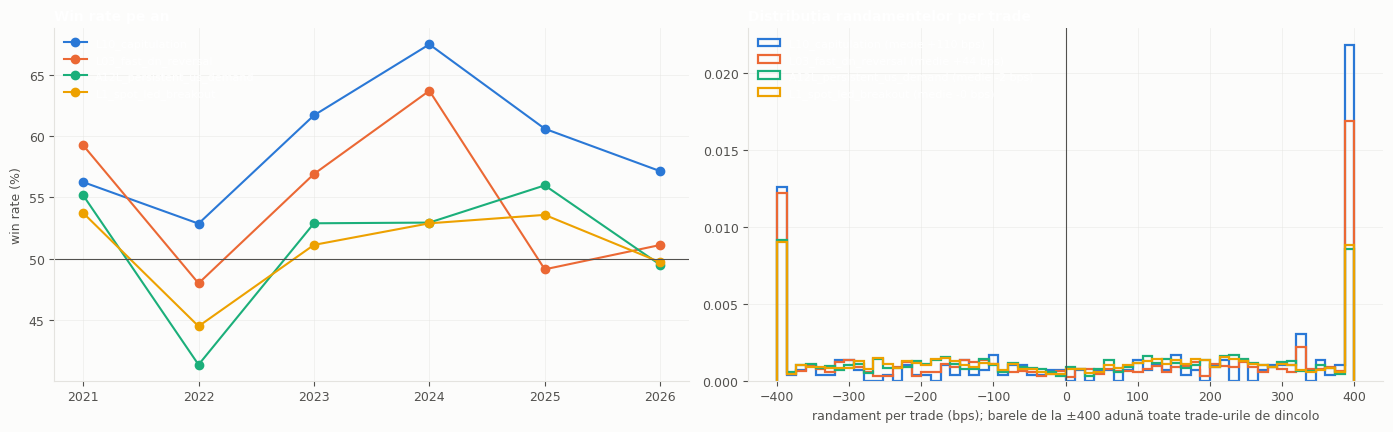

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
wr = TRADES.groupby([TRADES.t0.dt.year, "strategy"]).net_ret.apply(lambda s: (s > 0).mean()).unstack()[NAMES]
for n in NAMES:
    axes[0].plot(wr.index, wr[n] * 100, marker="o", ms=6, color=COLOR[n], label=n)
axes[0].axhline(50, color="#52514e", lw=0.8); axes[0].set_ylabel("win rate (%)")
axes[0].set_title("Win rate pe an", loc="left"); axes[0].legend(frameon=False, fontsize=8)

bins = np.linspace(-400, 400, 61)
for n in NAMES:
    v = TRADES.loc[TRADES.strategy == n, "net_ret"] * 1e4
    axes[1].hist(v.clip(-400, 400), bins=bins, density=True, histtype="step", lw=1.6, color=COLOR[n], label=f"{n} (medie {v.mean():+.0f} bps)")
axes[1].axvline(0, color="#52514e", lw=0.8); axes[1].set_xlabel("randament per trade (bps); barele de la ±400 adună toate trade-urile de dincolo")
axes[1].set_title("Distribuția randamentelor per trade", loc="left"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 11. Stabilitate: Sharpe pe ferestre mobile de 180 de zile

Arată dacă profitul vine constant sau doar din câteva perioade.

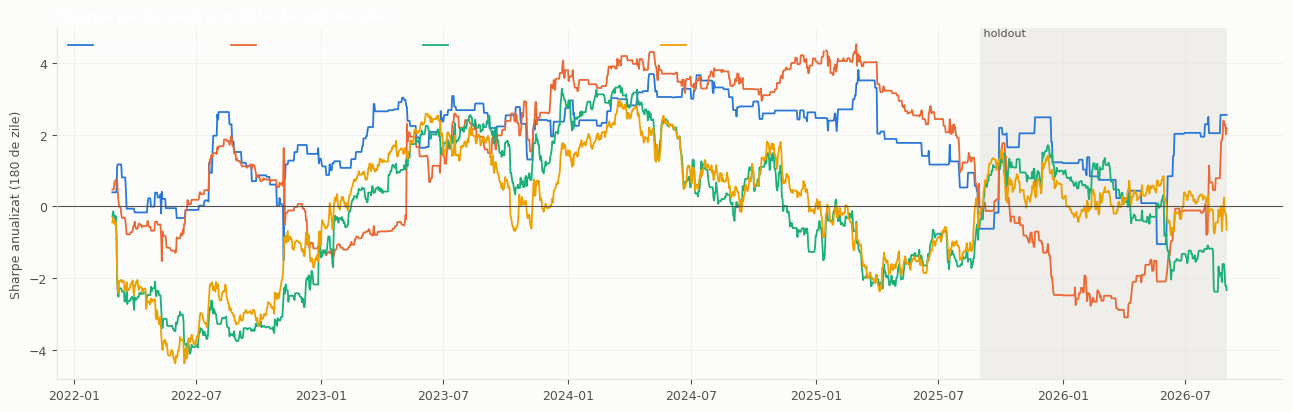

In [19]:
fig, ax = plt.subplots(figsize=(13, 4.2))
for n in NAMES:
    r = daily_pnl(TRADES[TRADES.strategy == n], start, end) / INITIAL_CAPITAL
    rs = r.rolling(180).mean() / r.rolling(180).std() * np.sqrt(ANN_DAYS)
    ax.plot(rs.index, rs.values, color=COLOR[n], lw=1.3, label=n)
ax.axhline(0, color="#52514e", lw=0.8); shade_holdout(ax)
ax.set_ylabel("Sharpe anualizat (180 de zile)"); ax.set_title("Sharpe pe fereastră mobilă de 180 de zile", loc="left")
ax.legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

## 12. Cât de diferite sunt strategiile între ele

Corelația PnL-ului zilnic și suprapunerea semnalelor. L10 e un subset al lui L03, iar A12L e un subset al lui L1. Dacă le combini, contează cât de mult se suprapun.

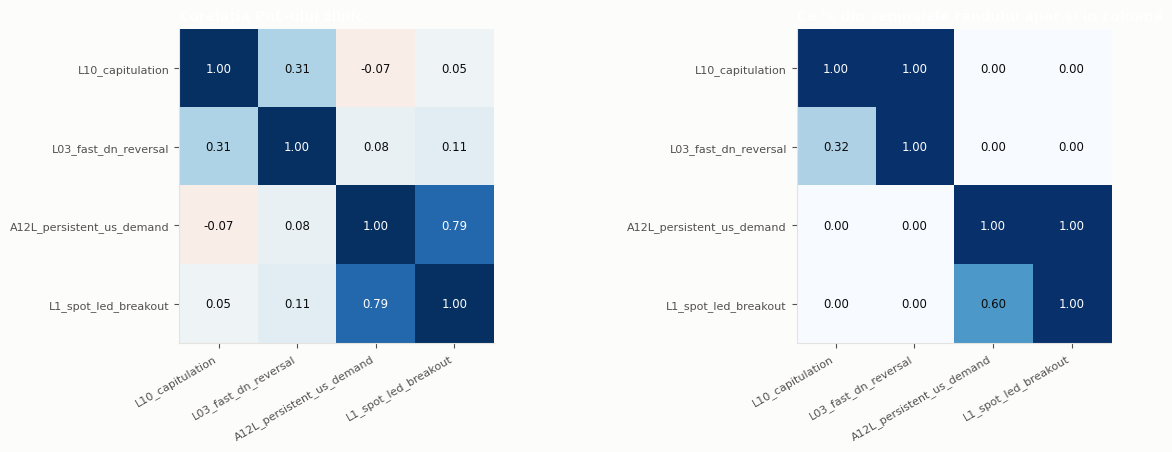

In [20]:
DP = pd.DataFrame({n: daily_pnl(TRADES[TRADES.strategy == n], start, end) for n in NAMES})
corr = DP[(DP != 0).any(axis=1)].corr()
sets = {n: set(TRADES.loc[TRADES.strategy == n, "t0"]) for n in NAMES}
overlap = pd.DataFrame({a: {b: len(sets[a] & sets[b]) / len(sets[a]) for b in NAMES} for a in NAMES}).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, M, ttl, cm, vmin in ((axes[0], corr, "Corelația PnL-ului zilnic", "RdBu", -1),
                             (axes[1], overlap, "Ce % din semnalele rândului apar și în coloană", "Blues", 0)):
    ax.imshow(M.values, cmap=cm, vmin=vmin, vmax=1)
    for (i, j), v in np.ndenumerate(M.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
    ax.set_xticks(range(len(NAMES)), NAMES, rotation=30, ha="right", fontsize=8); ax.set_yticks(range(len(NAMES)), NAMES, fontsize=8)
    ax.set_title(ttl, loc="left"); ax.grid(False)
plt.tight_layout(); plt.show()

## 13. Sensibilitatea la costuri

Cât rămâne din PnL-ul anual (USD) la diverse costuri dus-întors. La Binance spot taker, costul e ~20 bps dus-întors; cu BNB, VIP sau maker e ~5–15 bps.

PnL anual (USD) după costuri, toată perioada:
                            0 bps   5 bps  10 bps  20 bps
strategy                                                 
L10_capitulation           4837.0  4617.0  4397.0  3957.0
L03_fast_dn_reversal       5966.0  5282.0  4599.0  3232.0
A12L_persistent_us_demand  -581.0 -1752.0 -2922.0 -5264.0
L1_spot_led_breakout        -12.0 -1979.0 -3945.0 -7878.0

Cost de break-even (bps dus-întors) = media brută per trade:
strategy
L10_capitulation             109.9
L03_fast_dn_reversal          43.6
A12L_persistent_us_demand     -2.5
L1_spot_led_breakout          -0.0


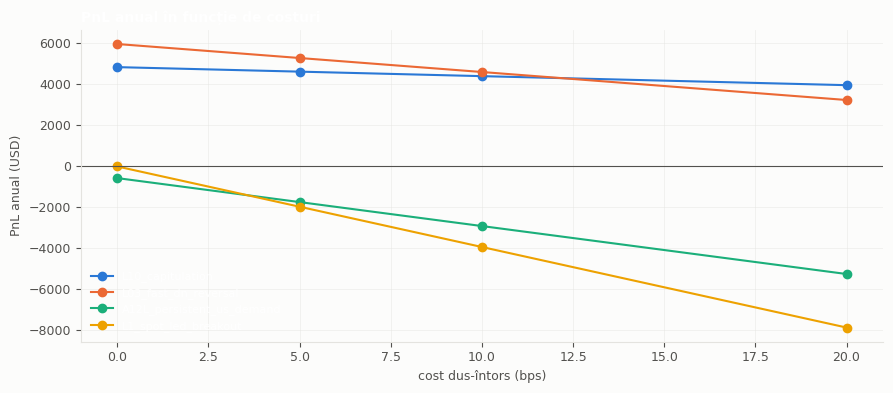

In [21]:
rows = {}
years_full = (end - start).days / 365.25
for c in COST_SCENARIOS_BPS:
    g = TRADES.assign(r=TRADES.gross_ret - c / 1e4).groupby("strategy").r
    rows[f"{c} bps"] = (g.sum() * TRADE_NOTIONAL / years_full).reindex(NAMES)
COSTS = pd.DataFrame(rows)
print("PnL anual (USD) după costuri, toată perioada:"); print(COSTS.round(0).to_string())
print("\nCost de break-even (bps dus-întors) = media brută per trade:")
print((TRADES.groupby("strategy").gross_ret.mean() * 1e4).reindex(NAMES).round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for n in NAMES:
    ax.plot(COST_SCENARIOS_BPS, COSTS.loc[n].values, marker="o", ms=6, color=COLOR[n], label=n)
ax.axhline(0, color="#52514e", lw=0.8); ax.set_xlabel("cost dus-întors (bps)"); ax.set_ylabel("PnL anual (USD)")
ax.set_title("PnL anual în funcție de costuri", loc="left"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 14. Export pentru meta-labeling

Semnalele, cu `side` și `t1`, pentru pasul tău de filtrare. `t1` e necesar pentru purged CV și pentru average uniqueness.

In [22]:
SIGNALS = TRADES[["t0", "t1", "strategy", "side", "ret", "t_value", "bin", "gross_ret", "period"]].copy()
SIGNALS["meta_label"] = (SIGNALS.gross_ret > 0).astype(int)
SIGNALS.to_parquet("primary_signals.parquet")
print(SIGNALS.groupby(["strategy", "period"]).size().unstack().reindex(NAMES).to_string())
SIGNALS.head()

period                      dev  holdout
strategy                                
L10_capitulation            195       25
L03_fast_dn_reversal        606       77
A12L_persistent_us_demand  1007      163
L1_spot_led_breakout       1688      277


,t0,t1,strategy,side,ret,t_value,bin,gross_ret,period,meta_label
0,2021-09-07 14:29:55.828000+00:00,2021-09-07 15:03:00.712000+00:00,L10_capitulation,1,-0.057831,-5.156276,-1.0,-0.057831,dev,0
1,2021-09-07 14:47:51.984000+00:00,2021-09-07 15:10:10.362000+00:00,L10_capitulation,1,-0.196353,-5.505846,-1.0,-0.196353,dev,0
2,2021-09-07 14:59:27.735000+00:00,2021-09-07 15:10:10.362000+00:00,L10_capitulation,1,-0.169359,-6.134556,-1.0,-0.169359,dev,0
3,2021-09-07 15:07:38.260000+00:00,2021-09-07 15:25:24.941000+00:00,L10_capitulation,1,0.109103,6.911528,1.0,0.109103,dev,1
4,2021-09-07 15:09:43.809000+00:00,2021-09-07 15:24:12.381000+00:00,L10_capitulation,1,0.222524,8.899210,1.0,0.222524,dev,1
